In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import KFold, GroupKFold, LeaveOneGroupOut, cross_val_predict, RandomizedSearchCV
from sklearn.metrics import r2_score, root_mean_squared_error

In [2]:
csv_path = "../results/tables/baza_kalibracyjna_UAV_PlanetScope_FVC.csv"
df = pd.read_csv(csv_path)
print(f"Początkowa liczba wierszy: {len(df)}")

df = df.replace([np.inf, -np.inf], np.nan).dropna().copy()

norm_indices = ['NDVI', 'SAVI', 'RENDVI', 'NDWI']
for idx in norm_indices:
    for prefix in ['UAV_', 'PS_']:
        col = f"{prefix}{idx}"
        if col in df.columns:
            df = df[df[col].between(-1.0, 1.0)]

df = df[df['UAV_EVI'].between(-1.0, 3.0) & df['PS_EVI'].between(-1.0, 3.0)]
df = df[df['UAV_CIre'].between(-1.0, 15.0) & df['PS_CIre'].between(-1.0, 15.0)]
df = df.reset_index(drop=True)

BLOCK_SIZE = 30.0
block_x = (df['x_center'] // BLOCK_SIZE).astype(int)
block_y = (df['y_center'] // BLOCK_SIZE).astype(int)
df['Block_ID'] = df['field_id'] + "_" + block_x.astype(str) + "_" + block_y.astype(str)

print(f"Liczba wierszy po oczyszczeniu: {len(df)}")
print(f"Pola w bazie: {df['field_id'].unique()} | Terminy nalotów ({df['flight_date'].nunique()}): {sorted(df['flight_date'].unique())}")
print(f"Utworzono {df['Block_ID'].nunique()} unikalnych bloków przestrzennych 30x30 m.\n")

# Diagnostyka średnich wartości w poszczególnych terminach (kontrola spójności radiometrycznej)
diag = df.groupby(['field_id', 'flight_date'])[['UAV_NDVI', 'PS_NDVI', 'UAV_SAVI', 'PS_SAVI', 'UAV_EVI', 'UAV_RENDVI']].mean().round(3)
display(diag)

Początkowa liczba wierszy: 18465
Liczba wierszy po oczyszczeniu: 18460
Pola w bazie: <StringArray>
['01W']
Length: 1, dtype: str | Terminy nalotów (7): ['2026-08-10', '2026-09-02', '2026-09-09', '2026-09-15', '2026-10-01', '2026-10-03', '2026-10-06']
Utworzono 59 unikalnych bloków przestrzennych 30x30 m.



UAV_NDVI  PS_NDVI  UAV_SAVI  PS_SAVI  UAV_EVI  \
field_id flight_date                                                  
01W      2026-08-10      0.584    0.771     0.405    0.569    0.419   
         2026-09-02      0.580    0.724     0.407    0.508    0.414   
         2026-09-09      0.522    0.721     0.364    0.520    0.363   
         2026-09-15      0.466    0.723     0.335    0.481    0.340   
         2026-10-01      0.438    0.722     0.318    0.481    0.312   
         2026-10-03      0.411    0.714     0.292    0.491    0.276   
         2026-10-06      0.437    0.716     0.319    0.477    0.313   

                      UAV_RENDVI  
field_id flight_date              
01W      2026-08-10        0.326  
         2026-09-02        0.347  
         2026-09-09        0.306  
         2026-09-15        0.291  
         2026-10-01        0.253  
         2026-10-03        0.233  
         2026-10-06        0.262

In [3]:
# ==============================================================================
# INŻYNIERIA CECH (100% CECH Z SATELITY PLANETSCOPE - ZERO WYCIEKU DANYCH Z UAV)
# ==============================================================================
df_clean = df.copy()

TARGETS_6 = ['UAV_NDVI', 'UAV_SAVI', 'UAV_EVI', 'UAV_RENDVI', 'UAV_CIre', 'UAV_NDWI']
PS_IND_6  = ['PS_NDVI', 'PS_SAVI', 'PS_EVI', 'PS_RENDVI', 'PS_CIre', 'PS_NDWI']
PS_BANDS_5 = [c for c in ['PS_Blue', 'PS_Green', 'PS_Red', 'PS_RedEdge', 'PS_NIR'] if c in df_clean.columns]

PS_BASE = PS_IND_6 + PS_BANDS_5

# 1. Cechy interakcji glebowo-roślinnych (satelitarny ekwiwalent FVC i saturacji łanu)
df_clean['PS_soil_diff']  = df_clean['PS_NDVI'] - df_clean['PS_SAVI']
df_clean['PS_soil_ratio'] = df_clean['PS_SAVI'] / (df_clean['PS_NDVI'] + 1e-6)
df_clean['PS_re_ratio']   = df_clean['PS_RENDVI'] / (df_clean['PS_NDVI'] + 1e-6)

# 2. Standaryzacja wewnątrzpolowa (Z-Score) - usuwa dryft atmosferyczny między terminami
for col in PS_IND_6:
    mean_val = df_clean.groupby(['field_id', 'flight_date'])[col].transform('mean')
    std_val  = df_clean.groupby(['field_id', 'flight_date'])[col].transform('std')
    df_clean[f'{col}_zscore'] = (df_clean[col] - mean_val) / (std_val + 1e-6)

# Zestaw główny wdrożeniowy (Tylko Satelita: 20 cech)
FEATURES_SAT_ENH = (
    PS_BASE + 
    ['PS_soil_diff', 'PS_soil_ratio', 'PS_re_ratio'] + 
    [f'{col}_zscore' for col in PS_IND_6]
)

# Zestaw referencyjny z FVC z drona (do wykazania wpływu pokrycia roślinnością w pracy)
FEATURES_WITH_FVC = FEATURES_SAT_ENH + ['FVC']

X_enh   = df_clean[FEATURES_SAT_ENH].values
X_fvc   = df_clean[FEATURES_WITH_FVC].values
groups_block = df_clean['Block_ID'].values
groups_time  = df_clean['flight_date'].values

print(f"Zbudowano macierz wejściową X_enh o wymiarach: {X_enh.shape} ({len(FEATURES_SAT_ENH)} cech satelitarnych).")

Zbudowano macierz wejściową X_enh o wymiarach: (18460, 20) (20 cech satelitarnych).


In [4]:
# ==============================================================================
# KROK 1: TUNING HIPERPARAMETRÓW (Spatial RandomizedSearchCV na blokach 30x30m)
# ==============================================================================
cv_random = KFold(n_splits=5, shuffle=True, random_state=42)
cv_block  = GroupKFold(n_splits=5)
cv_time   = LeaveOneGroupOut()

# Przestrzeń poszukiwań hiperparametrów dla Random Forest
param_dist = {
    'n_estimators': [150, 200, 300],
    'max_depth': [8, 10, 12, 15, None],
    'min_samples_leaf': [4, 6, 8, 12, 16],
    'min_samples_split': [5, 10, 20],
    'max_features': ['sqrt', 0.5, 0.7, 1.0]
}

print("Szukanie optymalnych hiperparametrów (Spatial RandomizedSearchCV)...")
rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)

# Optymalizujemy na głównym wskaźniku referencyjnym (UAV_NDVI) względem bloków 30x30m
search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist,
    n_iter=12,                # Testujemy 12 losowych kombinacji (szybko i skutecznie)
    scoring='r2',
    cv=cv_block,              # Kluczowe: tuning na walidacji blokowej chroni przed przeuczeniem!
    random_state=42,
    n_jobs=-1
)

search.fit(X_enh, df_clean['UAV_NDVI'].values, groups=groups_block)

best_rf_params = search.best_params_
best_rf_params['random_state'] = 42
best_rf_params['n_jobs'] = -1

print(f" -> Najlepsze wyłonione parametry: {search.best_params_}")
print(f" -> Najlepsze R2 (UAV_NDVI, blokowa) z tuningu: {search.best_score_:.3f}\n")

# ==============================================================================
# KROK 2: WALIDACJA KRZYŻOWA NA ZOPTYMALIZOWANYM MODELU DLA 6 WSKAŹNIKÓW
# ==============================================================================
wyniki_walidacji = []

for target in TARGETS_6:
    y = df_clean[target].values
    model = RandomForestRegressor(**best_rf_params)
    
    # 1. Walidacja z udziałem FVC (punkt odniesienia - górny pułap dokładności)
    pred_fvc = cross_val_predict(model, X_fvc, y, cv=cv_block, groups=groups_block, n_jobs=-1)
    
    # 2. Walidacja Losowa K-Fold (tylko satelita)
    pred_rand = cross_val_predict(model, X_enh, y, cv=cv_random, n_jobs=-1)
    
    # 3. Walidacja Blokowa 30x30m (tylko satelita - główny wynik wdrożeniowy)
    pred_block = cross_val_predict(model, X_enh, y, cv=cv_block, groups=groups_block, n_jobs=-1)
    df_clean[f"Pred_{target}"] = pred_block  # Zapis predykcji do generowania map!
    
    # 4. Walidacja Czasowa Leave-One-Date-Out (tylko satelita)
    pred_time = cross_val_predict(model, X_enh, y, cv=cv_time, groups=groups_time, n_jobs=-1)
    r2_per_day = [
        np.corrcoef(y[groups_time == dt], pred_time[groups_time == dt])[0, 1] ** 2 
        for dt in np.unique(groups_time)
    ]
    
    wyniki_walidacji.append({
        'Wskaźnik': target,
        'R2_Blokowa (z FVC)': round(r2_score(y, pred_fvc), 3),
        'R2_Losowa (K-Fold)': round(r2_score(y, pred_rand), 3),
        'R2_Blokowa (30x30m)': round(r2_score(y, pred_block), 3),
        'RMSE_Blokowa': round(root_mean_squared_error(y, pred_block), 3),
        'R2_Czasowa (Wzorzec)': round(np.mean(r2_per_day), 3),
        'RMSE_Czasowa': round(root_mean_squared_error(y, pred_time), 3)
    })

df_podsumowanie = pd.DataFrame(wyniki_walidacji)
df_podsumowanie.to_csv("../results/tables/finalne_wyniki_walidacji_RF.csv", index=False)
print("=== TABELA PODSUMOWUJĄCA WALIDACJĘ PO TUNINGU HIPERPARAMETRÓW ===")
display(df_podsumowanie)

Szukanie optymalnych hiperparametrów (Spatial RandomizedSearchCV)...
 -> Najlepsze wyłonione parametry: {'n_estimators': 150, 'min_samples_split': 10, 'min_samples_leaf': 16, 'max_features': 'sqrt', 'max_depth': 8, 'random_state': 42, 'n_jobs': -1}
 -> Najlepsze R2 (UAV_NDVI, blokowa) z tuningu: 0.682

=== TABELA PODSUMOWUJĄCA WALIDACJĘ PO TUNINGU HIPERPARAMETRÓW ===


,Wskaźnik,R2_Blokowa (z FVC),R2_Losowa (K-Fold),R2_Blokowa (30x30m),RMSE_Blokowa,R2_Czasowa (Wzorzec),RMSE_Czasowa
0,UAV_NDVI,0.827,0.732,0.684,0.069,0.562,0.083
1,UAV_SAVI,0.508,0.502,0.432,0.085,0.317,0.090
2,UAV_EVI,0.523,0.517,0.448,0.098,0.323,0.105
3,UAV_RENDVI,0.718,0.649,0.583,0.055,0.524,0.067
4,UAV_CIre,0.713,0.656,0.587,0.257,0.515,0.315
5,UAV_NDWI,0.769,0.739,0.687,0.058,0.589,0.068


=== ZESTAWIENIE MODELI ML (Walidacja Blokowa 30x30m) ===


,Wskaźnik,1_Liniowa_R2,2_RandomForest_R2,3_GradBoosting_R2,Liniowa_RMSE,RF_RMSE,GB_RMSE
0,UAV_NDVI,0.654,0.684,0.677,0.072,0.069,0.069
1,UAV_SAVI,0.409,0.432,0.409,0.086,0.085,0.086
2,UAV_EVI,0.419,0.448,0.425,0.100,0.098,0.100
3,UAV_RENDVI,0.558,0.583,0.572,0.057,0.055,0.056
4,UAV_CIre,0.563,0.587,0.581,0.264,0.257,0.259
5,UAV_NDWI,0.669,0.687,0.685,0.060,0.058,0.058


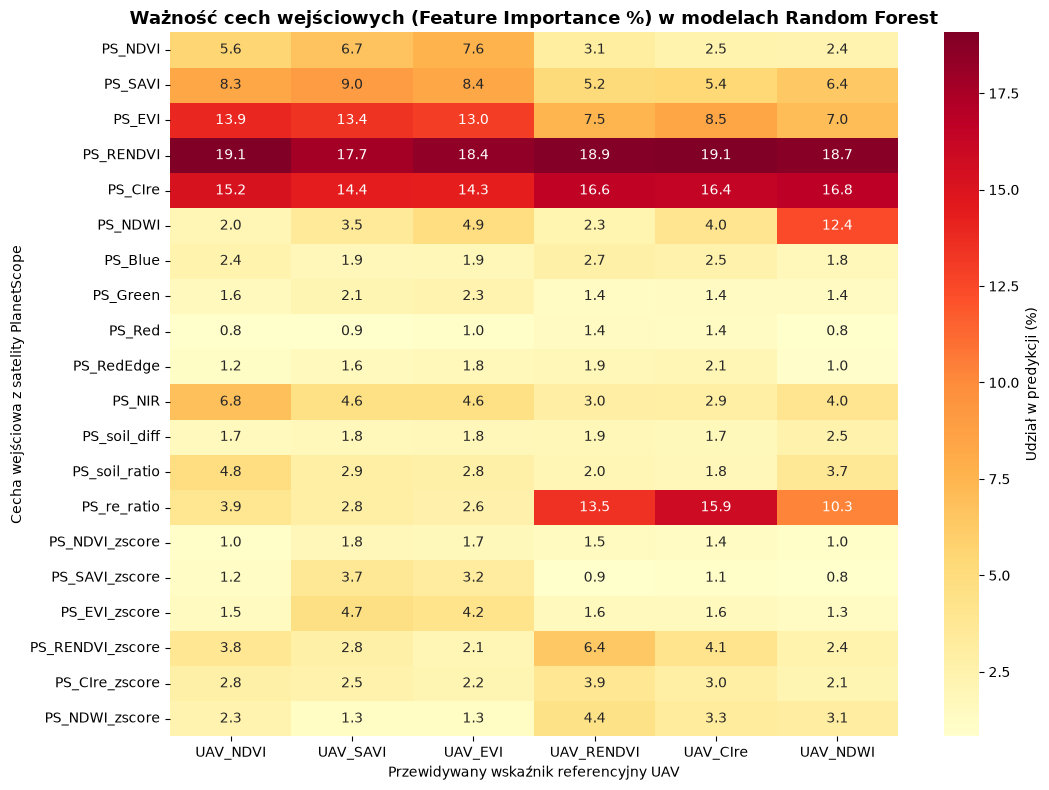

In [7]:
# ==============================================================================
# PORÓWNANIE 3 ALGORYTMÓW ML ORAZ ANALIZA WAŻNOŚCI CECH (FEATURE IMPORTANCE)
# ==============================================================================
porownanie = []
importances_dict = {}

for target in TARGETS_6:
    y = df_clean[target].values
    
    # A. Regresja Liniowa z regularyzacją L2 (Ridge - Baseline)
    model_lin = Ridge(alpha=1.0)
    pred_lin = cross_val_predict(model_lin, X_enh, y, cv=cv_block, groups=groups_block)
    
    # B. Random Forest (Bagging) - wykorzystujemy zapisane predykcje blokowe z Komórki 3
    pred_rf = df_clean[f"Pred_{target}"].values
    
    # C. Histogram Gradient Boosting (Boosting - odpowiednik LightGBM)
    model_gb = HistGradientBoostingRegressor(
        max_iter=200, max_depth=6, learning_rate=0.05, min_samples_leaf=15, random_state=42
    )
    pred_gb = cross_val_predict(model_gb, X_enh, y, cv=cv_block, groups=groups_block)
    
    porownanie.append({
        'Wskaźnik': target,
        '1_Liniowa_R2': round(r2_score(y, pred_lin), 3),
        '2_RandomForest_R2': round(r2_score(y, pred_rf), 3),
        '3_GradBoosting_R2': round(r2_score(y, pred_gb), 3),
        'Liniowa_RMSE': round(root_mean_squared_error(y, pred_lin), 3),
        'RF_RMSE': round(root_mean_squared_error(y, pred_rf), 3),
        'GB_RMSE': round(root_mean_squared_error(y, pred_gb), 3)
    })
    
    # Dopasowanie modelu RF na pełnym zbiorze do odczytu Feature Importance
    rf_full = RandomForestRegressor(**best_rf_params)
    rf_full.fit(X_enh, y)
    importances_dict[target] = rf_full.feature_importances_ * 100

df_algorytmy = pd.DataFrame(porownanie)
df_algorytmy.to_csv("../results/tables/porownanie_algorytmow_ML.csv", index=False)
print("=== ZESTAWIENIE MODELI ML (Walidacja Blokowa 30x30m) ===")
display(df_algorytmy)

# Wykres Ważności Cech (Feature Importance)
df_imp = pd.DataFrame(importances_dict, index=FEATURES_SAT_ENH)

plt.figure(figsize=(11, 8))
sns.heatmap(df_imp, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={'label': 'Udział w predykcji (%)'})
plt.title("Ważność cech wejściowych (Feature Importance %) w modelach Random Forest", fontweight='bold', fontsize=13)
plt.ylabel("Cecha wejściowa z satelity PlanetScope")
plt.xlabel("Przewidywany wskaźnik referencyjny UAV")
plt.tight_layout()
plt.savefig("../results/figures/wykres_feature_importance_RF.png", dpi=300)
plt.show()

Rysowanie map -> Wskaźnik: NDVI | Pole: 01W | Data: 2026-09-15 | Liczba oczek 3x3m: 2715


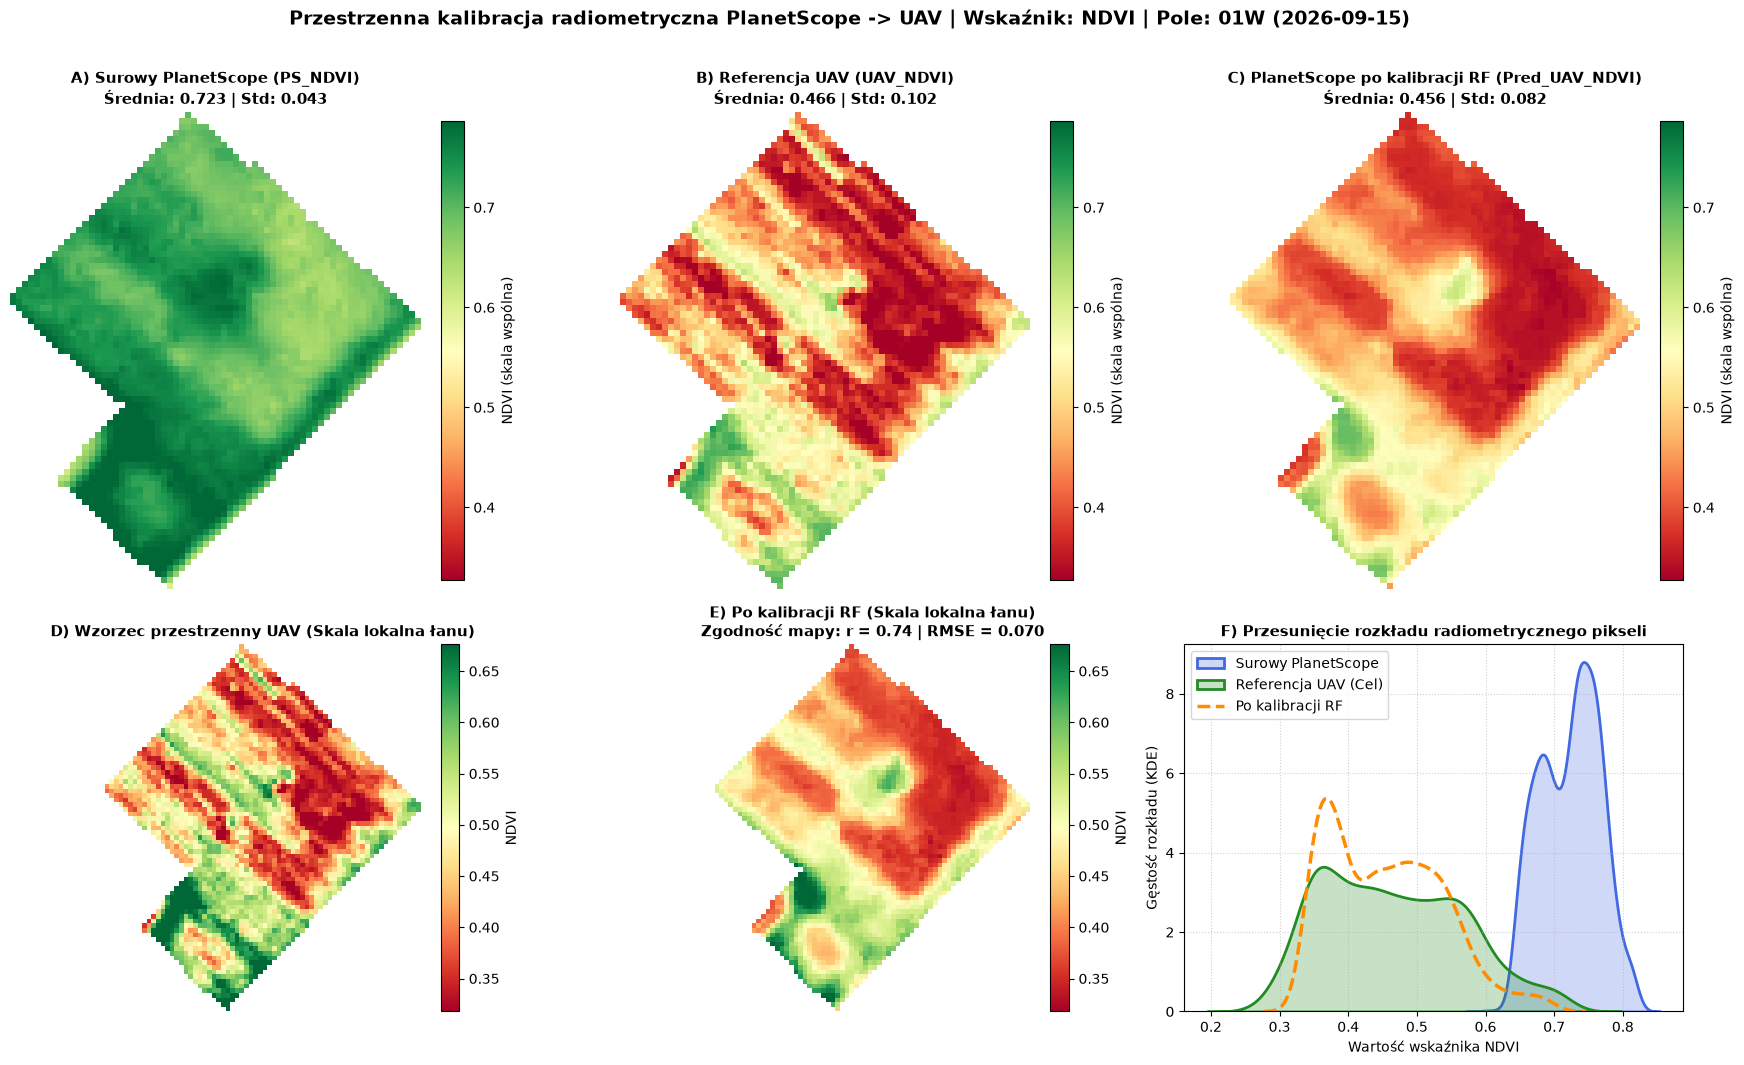

In [14]:
# ==============================================================================
# GENERATOR MAP PORÓWNAWCZYCH (SATELITA vs DRON vs PO KALIBRACJI RF)
# ==============================================================================
IDX_NAME = 'NDVI'            # Możesz zmienić np. na: 'RENDVI', 'CIre', 'SAVI', 'EVI', 'NDWI'
WYBRANA_DATA = '2026-09-15'  # Dostępne: '2026-08-10', '2026-09-02', '2026-09-09', '2026-09-15', '2026-10-01', '2026-10-03', '2026-10-06'

col_ps   = f"PS_{IDX_NAME}"
col_uav  = f"UAV_{IDX_NAME}"
col_pred = f"Pred_UAV_{IDX_NAME}"

df_date = df_clean[df_clean['flight_date'] == WYBRANA_DATA]
WYBRANE_POLE = df_date['field_id'].value_counts().index[0]
sub = df_date[df_date['field_id'] == WYBRANE_POLE].copy()

print(f"Rysowanie map -> Wskaźnik: {IDX_NAME} | Pole: {WYBRANE_POLE} | Data: {WYBRANA_DATA} | Liczba oczek 3x3m: {len(sub)}")

# Odtworzenie siatki 2D z kolumn 'row' i 'col'
r_min, r_max = int(sub['row'].min()), int(sub['row'].max())
c_min, c_max = int(sub['col'].min()), int(sub['col'].max())

shape_2d = (r_max - r_min + 1, c_max - c_min + 1)
grid_ps   = np.full(shape_2d, np.nan)
grid_uav  = np.full(shape_2d, np.nan)
grid_pred = np.full(shape_2d, np.nan)

rows_idx = sub['row'].astype(int).values - r_min
cols_idx = sub['col'].astype(int).values - c_min

grid_ps[rows_idx, cols_idx]   = sub[col_ps].values
grid_uav[rows_idx, cols_idx]  = sub[col_uav].values
grid_pred[rows_idx, cols_idx] = sub[col_pred].values

# Skale barwne (percentyle 2-98)
all_vals = np.concatenate([sub[col_ps].values, sub[col_uav].values, sub[col_pred].values])
vmin_global, vmax_global = np.nanpercentile(all_vals, 2), np.nanpercentile(all_vals, 98)

uav_vals = np.concatenate([sub[col_uav].values, sub[col_pred].values])
vmin_local, vmax_local = np.nanpercentile(uav_vals, 2), np.nanpercentile(uav_vals, 98)

fig = plt.figure(figsize=(18, 10.5))
gs = fig.add_gridspec(2, 3, height_ratios=[1.3, 1])

cmap_veg = plt.cm.RdYlGn.copy()
cmap_veg.set_bad(color='white')

# Wiersz 1: Skala globalna
titles_top = [
    f"A) Surowy PlanetScope ({col_ps})\nŚrednia: {sub[col_ps].mean():.3f} | Std: {sub[col_ps].std():.3f}",
    f"B) Referencja UAV ({col_uav})\nŚrednia: {sub[col_uav].mean():.3f} | Std: {sub[col_uav].std():.3f}",
    f"C) PlanetScope po kalibracji RF ({col_pred})\nŚrednia: {sub[col_pred].mean():.3f} | Std: {sub[col_pred].std():.3f}"
]
for i, g in enumerate([grid_ps, grid_uav, grid_pred]):
    ax = fig.add_subplot(gs[0, i])
    im = ax.imshow(g, cmap=cmap_veg, vmin=vmin_global, vmax=vmax_global)
    ax.set_title(titles_top[i], fontweight='bold', fontsize=11)
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label=f"{IDX_NAME} (skala wspólna)")


# Wiersz 2: Skala lokalna łanu + Histogram KDE
ax_uav_zoom = fig.add_subplot(gs[1, 0])
im_uz = ax_uav_zoom.imshow(grid_uav, cmap=cmap_veg, vmin=vmin_local, vmax=vmax_local)
ax_uav_zoom.set_title("D) Wzorzec przestrzenny UAV (Skala lokalna łanu)", fontweight='bold', fontsize=11)
ax_uav_zoom.axis('off')
plt.colorbar(im_uz, ax=ax_uav_zoom, fraction=0.046, pad=0.04, label=IDX_NAME)

ax_pred_zoom = fig.add_subplot(gs[1, 1])
im_pz = ax_pred_zoom.imshow(grid_pred, cmap=cmap_veg, vmin=vmin_local, vmax=vmax_local)
r_map = np.corrcoef(sub[col_uav], sub[col_pred])[0, 1]
rmse_map = np.sqrt(np.mean((sub[col_uav] - sub[col_pred]) ** 2))
ax_pred_zoom.set_title(f"E) Po kalibracji RF (Skala lokalna łanu)\nZgodność mapy: r = {r_map:.2f} | RMSE = {rmse_map:.3f}", fontweight='bold', fontsize=11)
ax_pred_zoom.axis('off')
plt.colorbar(im_pz, ax=ax_pred_zoom, fraction=0.046, pad=0.04, label=IDX_NAME)

ax_kde = fig.add_subplot(gs[1, 2])
sns.kdeplot(sub[col_ps], ax=ax_kde, color='royalblue', fill=True, alpha=0.25, linewidth=2, label='Surowy PlanetScope')
sns.kdeplot(sub[col_uav], ax=ax_kde, color='forestgreen', fill=True, alpha=0.25, linewidth=2, label='Referencja UAV (Cel)')
sns.kdeplot(sub[col_pred], ax=ax_kde, color='darkorange', linestyle='--', linewidth=2.5, label='Po kalibracji RF')
ax_kde.set_title("F) Przesunięcie rozkładu radiometrycznego pikseli", fontweight='bold', fontsize=11)
ax_kde.set_xlabel(f"Wartość wskaźnika {IDX_NAME}")
ax_kde.set_ylabel("Gęstość rozkładu (KDE)")
ax_kde.grid(True, linestyle=':', alpha=0.6)
ax_kde.legend(loc='upper left')

plt.suptitle(f"Przestrzenna kalibracja radiometryczna PlanetScope -> UAV | Wskaźnik: {IDX_NAME} | Pole: {WYBRANE_POLE} ({WYBRANA_DATA})", 
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()

out_file = f"../results/figures/mapa_kalibracja_{IDX_NAME}_{WYBRANE_POLE}_{WYBRANA_DATA}.png"
plt.savefig(out_file, dpi=300, bbox_inches='tight')
plt.show()